# 02 · 需求预测：方法 A、B、C

**任务：** 对每个“周 × 门店 × 商品”，只用过去的数据预测**下一周**的销量。

| 方法 | 思路 |
| --- | --- |
| A. 移动平均 | 预测 = 过去 4 周的平均销量 |
| B. 季节性朴素法 | 预测 = 52 周前同一周的销量 |
| C. LightGBM | 梯度提升树模型，用过去的特征学习 |

**评价指标：** MAE（平均绝对误差），即误差绝对值的平均，单位为件/周。

**输出：** `forecasts.csv`，包含验证集（2016）和测试集（2017）上的三种预测，供 notebook 03 使用。

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from pathlib import Path

DATA = Path("../data")
FIG = Path("../figures")

weekly = pd.read_csv(DATA / "weekly.csv", parse_dates=["week"])
weekly = weekly.sort_values(["store", "item", "week"]).reset_index(drop=True)
print(weekly.shape)
weekly.head()

(130000, 5)


,week,store,item,sales,split
0,2013-01-07,1,1,66,train
1,2013-01-14,1,1,80,train
2,2013-01-21,1,1,70,train
3,2013-01-28,1,1,86,train
4,2013-02-04,1,1,82,train


## 1. 只用过去的数据构造特征

`shift(k)` 在每个“门店 × 商品”内部取 **k 周前**的值，保证模型看不到未来（防止数据泄露）。

例：某序列连续 4 周销量为 90、100、110、100，则第 5 周这一行：
- `lag1` = 100（上一周）
- `roll4` = (90 + 100 + 110 + 100) / 4 = 100

**关于 2017 年：** 预测是一步向前的。周一决定订货时，上周的销量已经知道，因此测试期可以使用 2017 年截至上周的真实销量，这不属于数据泄露。

In [29]:
g = weekly.groupby(["store", "item"])["sales"]

weekly["lag1"] = g.shift(1)                                   # 上一周
weekly["lag52"] = g.shift(52)                                 # 去年同一周
weekly["roll4"] = g.transform(lambda s: s.shift(1).rolling(4).mean())        # 过去 4 周平均
weekly["roll4_ly"] = g.transform(lambda s: s.shift(53).rolling(4).mean())    # 去年同期的 4 周平均

weekly["week_of_year"] = weekly["week"].dt.isocalendar().week.astype(int).clip(upper=52)  # 第 53 周按第 52 周处理
weekly["month"] = weekly["week"].dt.month

weekly[["week", "store", "item", "sales", "lag1", "lag52", "roll4", "roll4_ly"]].iloc[52:58]

,week,store,item,sales,lag1,lag52,roll4,roll4_ly
52,2014-01-06,1,1,95,91.0,66.0,86.50,NaN
53,2014-01-13,1,1,106,95.0,80.0,90.75,NaN
54,2014-01-20,1,1,107,106.0,70.0,97.00,NaN
55,2014-01-27,1,1,85,107.0,86.0,99.75,NaN
56,2014-02-03,1,1,105,85.0,82.0,98.25,75.5
57,2014-02-10,1,1,104,105.0,80.0,100.75,79.5


**数据泄露检查：** 第 t 周的 `lag1` 必须等于第 t−1 周的销量。

In [30]:
s = weekly[(weekly["store"] == 1) & (weekly["item"] == 1)].reset_index(drop=True)
assert (s["lag1"].iloc[1:].values == s["sales"].iloc[:-1].values).all()
assert (s["lag52"].iloc[52:].values == s["sales"].iloc[:-52].values).all()
print("检查通过：lag1 和 lag52 只使用过去的周")

检查通过：lag1 和 lag52 只使用过去的周


## 2. 方法 A 和 B

这两种方法不需要训练，预测值就是对应的特征。

In [31]:
weekly["pred_A"] = weekly["roll4"]
weekly["pred_B"] = weekly["lag52"]

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

valid = weekly[weekly["split"] == "valid"]
print("验证集（2016）MAE:")
print("  A. 移动平均:  ", round(mae(valid["sales"], valid["pred_A"]), 1))
print("  B. 季节性朴素法:", round(mae(valid["sales"], valid["pred_B"]), 1))

验证集（2016）MAE:
  A. 移动平均:   30.1
  B. 季节性朴素法: 34.5


## 3. 方法 C：LightGBM

**树模型的局限：** 决策树的预测值不会超过训练数据中出现过的范围（无法外推）。销量逐年增长，2017 年的销量高于 2013–2015 年的任何值，直接预测销量会系统性低估。

**解决办法：** 让模型预测**今年销量是去年同期的多少倍**：

`ratio = sales / lag52`，预测值 = `预测的 ratio × lag52`。

例：去年同一周卖了 100 件，模型预测 ratio = 1.08，则预测值为 108 件。这个比值每年都在 1.0–1.15 左右，比较稳定。

**特征：**
- `growth_recent = roll4 / roll4_ly`：最近 4 周比去年同期高多少（近期增长）；
- `week_of_year`、`month`：季节性；
- `store`、`item`：不同门店和商品的差异。

In [32]:
weekly["growth_recent"] = weekly["roll4"] / weekly["roll4_ly"]
weekly["ratio"] = weekly["sales"] / weekly["lag52"]

FEATURES = ["growth_recent", "week_of_year", "month", "store", "item"]
for col in ["store", "item"]:
    weekly[col] = weekly[col].astype("category")   # 门店编号是类别，不是数值

# 只保留所有特征都存在的行（每条序列前 56 周没有足够的历史）
ok = weekly[FEATURES + ["lag52", "roll4_ly"]].notna().all(axis=1)
train = weekly[ok & (weekly["split"] == "train")]
valid = weekly[ok & (weekly["split"] == "valid")]
test = weekly[ok & (weekly["split"] == "test")]
print("行数: train", len(train), "| valid", len(valid), "| test", len(test))

行数: train 50000 | valid 26000 | test 26000


在 2014–2015 年上训练（2013 年还没有“去年同期”的数据），在 2016 年上验证。

参数：
- `n_estimators=400`：树的数量；
- `learning_rate=0.05`：每棵新树修正前面误差的步长；
- `objective="l1"`：直接最小化 MAE，与评价指标一致。

In [33]:
params = dict(objective="l1", n_estimators=400, learning_rate=0.05,
              num_leaves=31, min_child_samples=50, random_state=42, verbose=-1)

model = lgb.LGBMRegressor(**params)
model.fit(train[FEATURES], train["ratio"])

weekly.loc[valid.index, "pred_C"] = model.predict(valid[FEATURES]) * valid["lag52"]

v = weekly.loc[valid.index]
print("验证集（2016）MAE:")
print("  A. 移动平均:  ", round(mae(v["sales"], v["pred_A"]), 1))
print("  B. 季节性朴素法:", round(mae(v["sales"], v["pred_B"]), 1))
print("  C. LightGBM:  ", round(mae(v["sales"], v["pred_C"]), 1))

验证集（2016）MAE:
  A. 移动平均:   30.1
  B. 季节性朴素法: 34.5
  C. LightGBM:   25.5


**特征重要性：** `feature_importances_` 表示每个特征被用于分裂的次数。注意：按分裂次数计算的重要性偏向取值多的连续变量。

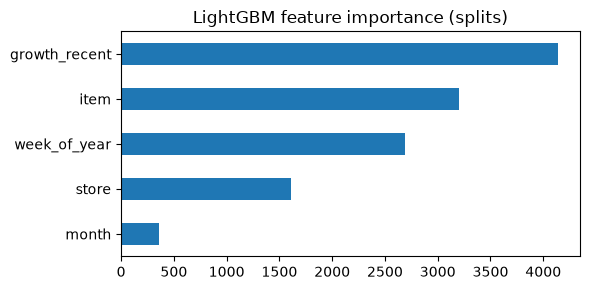

In [34]:
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6, 3))
imp.plot.barh(ax=ax)
ax.set_title("LightGBM feature importance (splits)")
plt.tight_layout()
plt.savefig(FIG / "02_feature_importance.png", dpi=150)
plt.show()

## 4. 测试集（2017）最终评估

所有设定（特征、参数）都只根据验证集确定。现在：
1. 用 2014–2016 年的数据重新训练模型；
2. 在 2017 年上**只计算一次**误差。

In [35]:
train_full = pd.concat([train, valid])
model_full = lgb.LGBMRegressor(**params)
model_full.fit(train_full[FEATURES], train_full["ratio"])

weekly.loc[test.index, "pred_C"] = model_full.predict(test[FEATURES]) * test["lag52"]

results = []
for split in ["valid", "test"]:
    part = weekly[ok & (weekly["split"] == split)]
    results.append({
        "split": split,
        "A. 移动平均": mae(part["sales"], part["pred_A"]),
        "B. 季节性朴素法": mae(part["sales"], part["pred_B"]),
        "C. LightGBM": mae(part["sales"], part["pred_C"]),
    })
results = pd.DataFrame(results).set_index("split").round(1)
results

,A. 移动平均,B. 季节性朴素法,C. LightGBM
split,,,
valid,30.1,34.5,25.5
test,30.8,25.6,24.8


**平均偏差：** 带符号的平均误差（预测 − 实际）。负值表示系统性低估，正值表示系统性高估。

In [36]:
t = weekly[ok & (weekly["split"] == "test")]
for m in ["pred_A", "pred_B", "pred_C"]:
    print(m, "测试集平均偏差:", round((t[m] - t["sales"]).mean(), 1), "件/周")

pred_A 测试集平均偏差: -0.7 件/周
pred_B 测试集平均偏差: -15.1 件/周
pred_C 测试集平均偏差: 9.7 件/周


## 5. 单条序列的预测（2017）

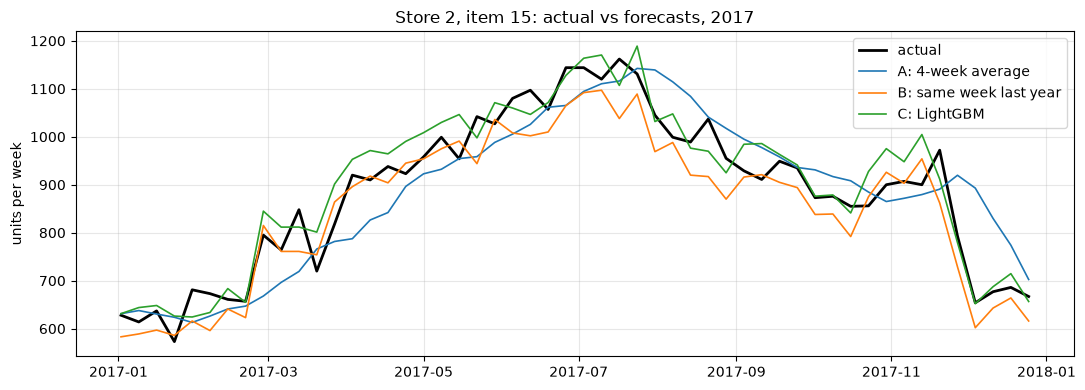

In [37]:
one = weekly[(weekly["store"] == 2) & (weekly["item"] == 15) & (weekly["split"] == "test")]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(one["week"], one["sales"], color="black", lw=2, label="actual")
ax.plot(one["week"], one["pred_A"], lw=1.2, label="A: 4-week average")
ax.plot(one["week"], one["pred_B"], lw=1.2, label="B: same week last year")
ax.plot(one["week"], one["pred_C"], lw=1.2, label="C: LightGBM")
ax.set_title("Store 2, item 15: actual vs forecasts, 2017")
ax.set_ylabel("units per week")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "02_forecasts_one_series.png", dpi=150)
plt.show()

## 6. 保存预测结果

In [38]:
out = weekly.loc[ok & weekly["split"].isin(["valid", "test"]),
                 ["week", "store", "item", "split", "sales", "pred_A", "pred_B", "pred_C"]]
out.to_csv(DATA / "forecasts.csv", index=False)
results.to_csv(DATA / "mae_results.csv")
print("已保存:", len(out), "行")

已保存: 52000 行


## 小结

- 测试集 MAE：A 30.8，B 25.6，C 24.8。LightGBM 比移动平均低约 19%，比季节性朴素法低约 3%。
- 方法 B 只重复去年同期的销量，没有考虑一年来的增长，平均偏差为 −15.1 件/周。
- LightGBM 在增长较快的 2014–2016 年上训练，而 2017 年增长放缓，平均偏差为 +9.7 件/周。模型没有根据测试集做任何调整。